In [2]:
import sys, os, importlib, tqdm
import pickle

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import netCDF4, h5py, scipy

In [3]:
import os

#targets = ['/mnt/d/ALOS1-Landfast/BeaufortSouth/' + el for el in os.listdir('/mnt/d/ALOS1-Landfast/BeaufortSouth/') if el[-5:] == 'cache']
bazinga, count = '', 0
for targ in os.listdir('/mnt/d/ALOS1-Landfast/BeaufortSouth/'):
    if targ[-5:] == 'cache':
        count += 1
        bazinga += f'{targ[:-11]}, '
bazinga, count

('ALPSRP059691410, ALPSRP059691420, ALPSRP062171410, ALPSRP068151420, ALPSRP070631410, ALPSRP070631420, ALPSRP072381420, ALPSRP094991420, ALPSRP099221420, ALPSRP121831420, ALPSRP126061420, ALPSRP167051410, ALPSRP167051420, ALPSRP169531410, ALPSRP169531420, ALPSRP171281410, ALPSRP171281420, ALPSRP173031420, ALPSRP173761410, ALPSRP173761420, ALPSRP176241410, ALPSRP177991410, ALPSRP177991420, ALPSRP178721410, ALPSRP200601410, ALPSRP200601420, ALPSRP202351420, ALPSRP206581420, ALPSRP256031420, ALPSRP274411410, ALPSRP274411420, ',
 31)

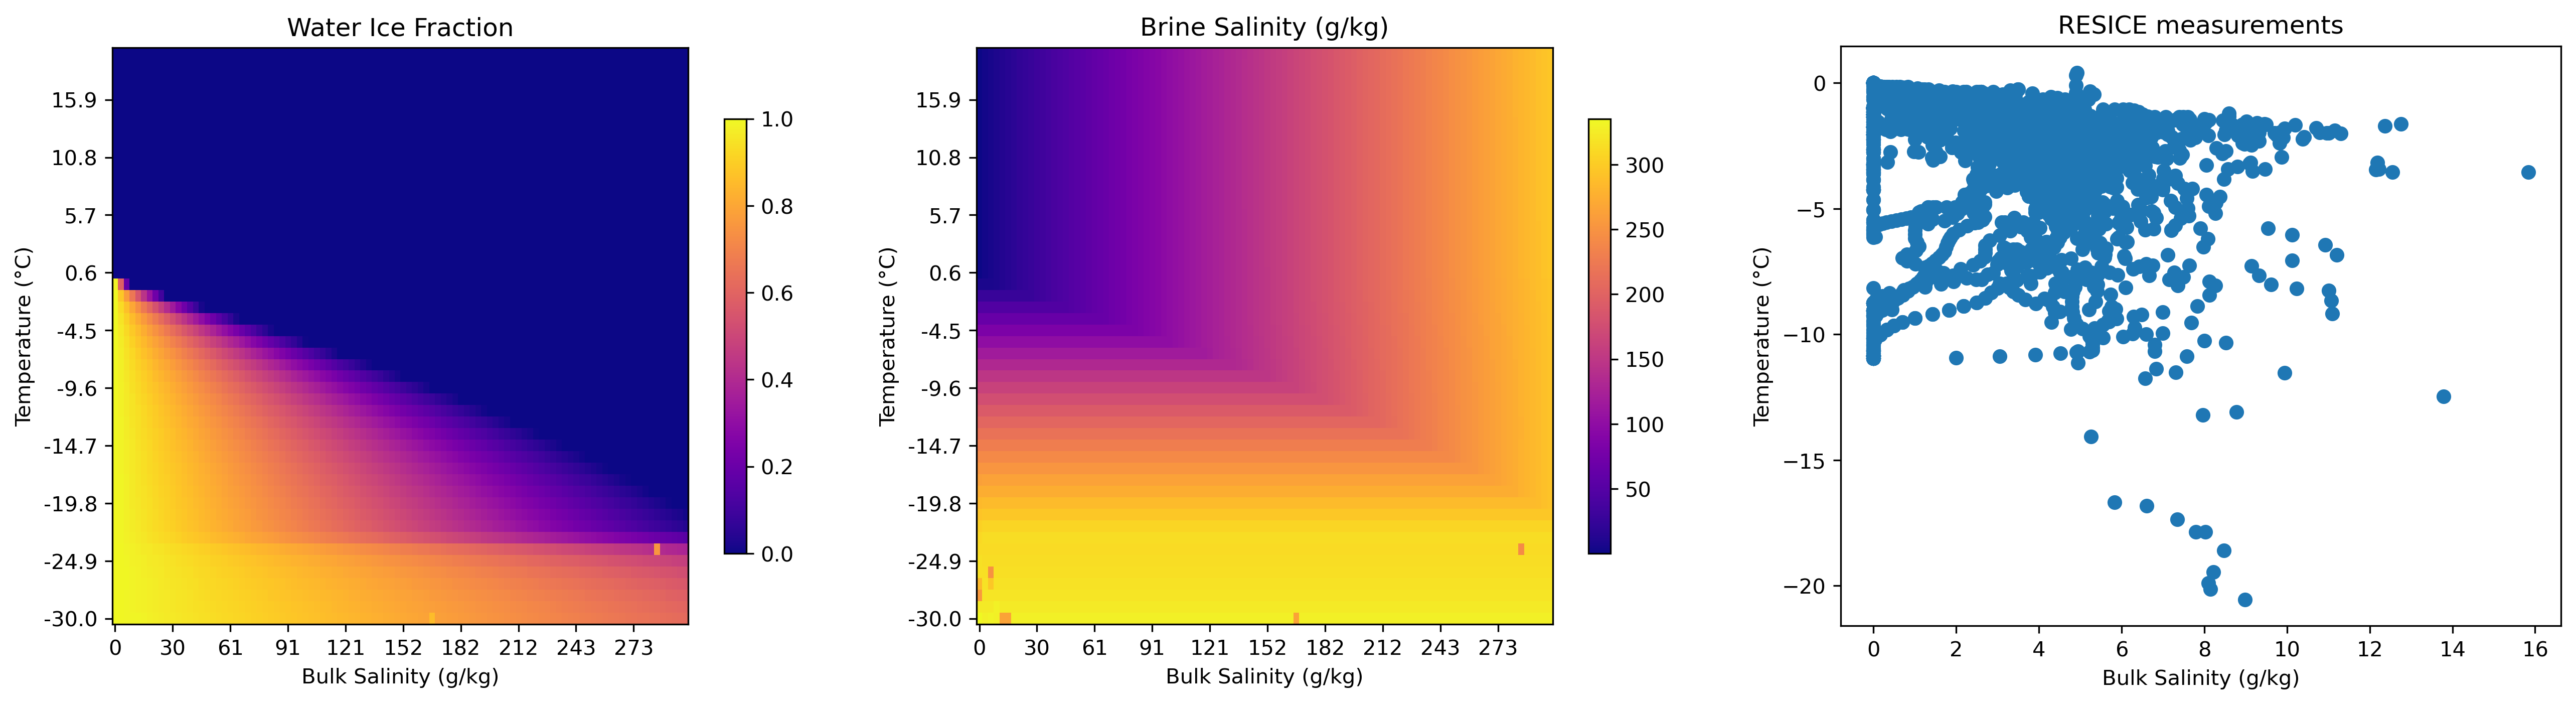

In [171]:
# -- BRACK2BING PHREEQC Freezing Simulation Reference Grid -- #

import brack2bing
icesim = brack2bing.LatticeSolver.load()

plt.figure(figsize=(21,5), dpi=300)
plt.subplot(1,3,1);
plt.imshow(icesim.ts_grid[0].cpu(), aspect=2, cmap='plasma'); plt.colorbar(shrink=0.75); plt.title('Water Ice Fraction'); plt.gca().invert_yaxis()
plt.ylabel('Temperature (°C)'); plt.yticks(np.arange(icesim.ts_grid.shape[1])[::5], icesim.t_idx.cpu().numpy().round(1).astype(str)[::5])
plt.xlabel('Bulk Salinity (g/kg)'); plt.xticks(np.arange(icesim.ts_grid.shape[2])[::10], icesim.s_idx.cpu().numpy().round(0).astype(int)[::10])
plt.subplot(1,3,2)
plt.imshow(icesim.ts_grid[1].cpu(), aspect=2, cmap='plasma'); plt.colorbar(shrink=0.75); plt.title('Brine Salinity (g/kg)'); plt.gca().invert_yaxis()
plt.ylabel('Temperature (°C)'); plt.yticks(np.arange(icesim.ts_grid.shape[1])[::5], icesim.t_idx.cpu().numpy().round(1).astype(str)[::5])
plt.xlabel('Bulk Salinity (g/kg)'); plt.xticks(np.arange(icesim.ts_grid.shape[2])[::10], icesim.s_idx.cpu().numpy().round(0).astype(int)[::10])
plt.subplot(1,3,3)
S, T = feed[:,0,:90].cpu(), feed[:,0,90:180].cpu()
plt.scatter(S[S != 35], T[S != 35]); plt.title('RESICE measurements')
plt.ylabel('Temperature (°C)'); plt.xlabel('Bulk Salinity (g/kg)');
#plt.show()
plt.savefig('/mnt/c/Users/user/Downloads/figure.png')
#plt.xlabel
#icesim.t_idx.cpu()

In [146]:
plt.scatter(
plt.ylabel('Temperature (°C)'); plt.yticks(np.arange(icesim.ts_grid.shape[1])[::5], icesim.t_idx.cpu().numpy().round(1).astype(str)[::5])
plt.xlabel('Bulk Salinity (g/kg)'); plt.xticks(np.arange(icesim.ts_grid.shape[2])[::10], icesim.s_idx.cpu().numpy().round(1).astype(str)[::10])

tensor([-30.0000, -28.9796, -27.9592, -26.9388, -25.9184, -24.8980, -23.8776,
        -22.8571, -21.8367, -20.8163, -19.7959, -18.7755, -17.7551, -16.7347,
        -15.7143, -14.6939, -13.6735, -12.6531, -11.6327, -10.6122,  -9.5918,
         -8.5714,  -7.5510,  -6.5306,  -5.5102,  -4.4898,  -3.4694,  -2.4490,
         -1.4286,  -0.4082,   0.6122,   1.6327,   2.6531,   3.6735,   4.6939,
          5.7143,   6.7347,   7.7551,   8.7755,   9.7959,  10.8163,  11.8367,
         12.8571,  13.8776,  14.8980,  15.9184,  16.9388,  17.9592,  18.9796,
         20.0000])

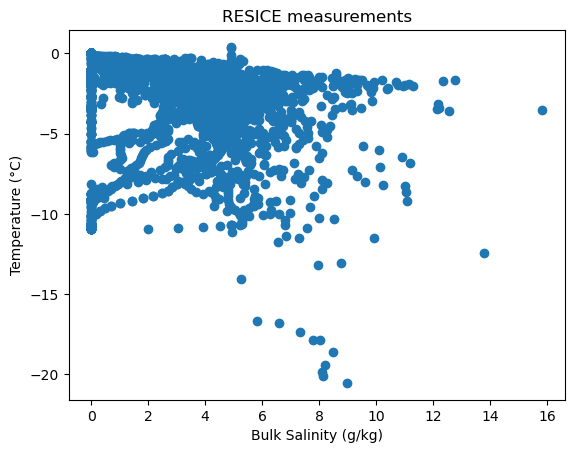

In [4]:
# -- Core forward simulation state progression -- #

import script_CoreExplorer; importlib.reload(script_CoreExplorer)
import util_collector; importlib.reload(util_collector)

def gen_feed(count=100, collector=None):
    train = script_CoreExplorer.get_randoms(count, reshape=False, collector=collector)
    # form covariance matrix
    rf = train['rf'].reshape([-1] + collector.h5f['rf'].attrs['fshape'].tolist()) #B,1,4,6
    rf, (B,C,P,I) = torch.as_tensor(rf).transpose(-1, -2), rf.shape
    rf_c = (rf[...,None] * rf.conj()[...,None,:]) # polarimetric covariance   ..  B,1,6,16
    trace = torch.diagonal(rf_c, 0, -2, -1).sum(dim=-1)
    rf_c = rf_c / trace[...,None,None] # normalized C4
    rf_c = rf_c.reshape(B,C,I*P*P) # B,1,6*4*4
    # create training vector
    train = [train['S'].real, train['T'].real, train['rho'].real, rf_c.real, rf_c.imag]
    feed = torch.cat([torch.as_tensor(el).flatten(1) for el in train], dim=1)[:,None,:].to('cuda', torch.float32)
    return feed, (C,I,P,P)

fn_ = 'em_resice.hdf5'

# -- get data shapes
train = script_CoreExplorer.get_randoms(1, fn=fn_, reshape=True)
train = [train['S'].real, train['T'].real, train['rho'].real, train['rf'].real, train['rf'].imag]
data_shapes = [el.shape[1:] for el in train]

# -- get data
collector = util_collector.Dataset(fn_)
feed, em_data_shape = gen_feed(100, collector);
floqs = collector.h5f.attrs['floq']
collector.close()

# adjust data shapes altered by gen_feed operation
data_shapes[-2], data_shapes[-1] = em_data_shape, em_data_shape
vl = [torch.as_tensor(el).prod() for el in data_shapes]; vlen=sum(vl)
incidence_n = len(floqs)

#np.concatenate(list(train.values()), axis=1).shape

In [145]:
#floqs
(feed[:,0,200] == 0.917).sum()

tensor(70, device='cuda:0')

torch.Size([1, 1, 1, 1, 90]) torch.Size([1, 1, 1, 90]) torch.Size([1, 1, 1, 120, 90])
torch.Size([1, 1, 1, 1, 90]) torch.Size([1, 1, 1, 90]) torch.Size([1, 1, 1, 120, 90])
torch.Size([1, 1, 1, 1, 90]) torch.Size([1, 1, 1, 90]) torch.Size([1, 1, 1, 120, 90])
torch.Size([1, 1, 1, 1, 90]) torch.Size([1, 1, 1, 90]) torch.Size([1, 1, 1, 120, 90])


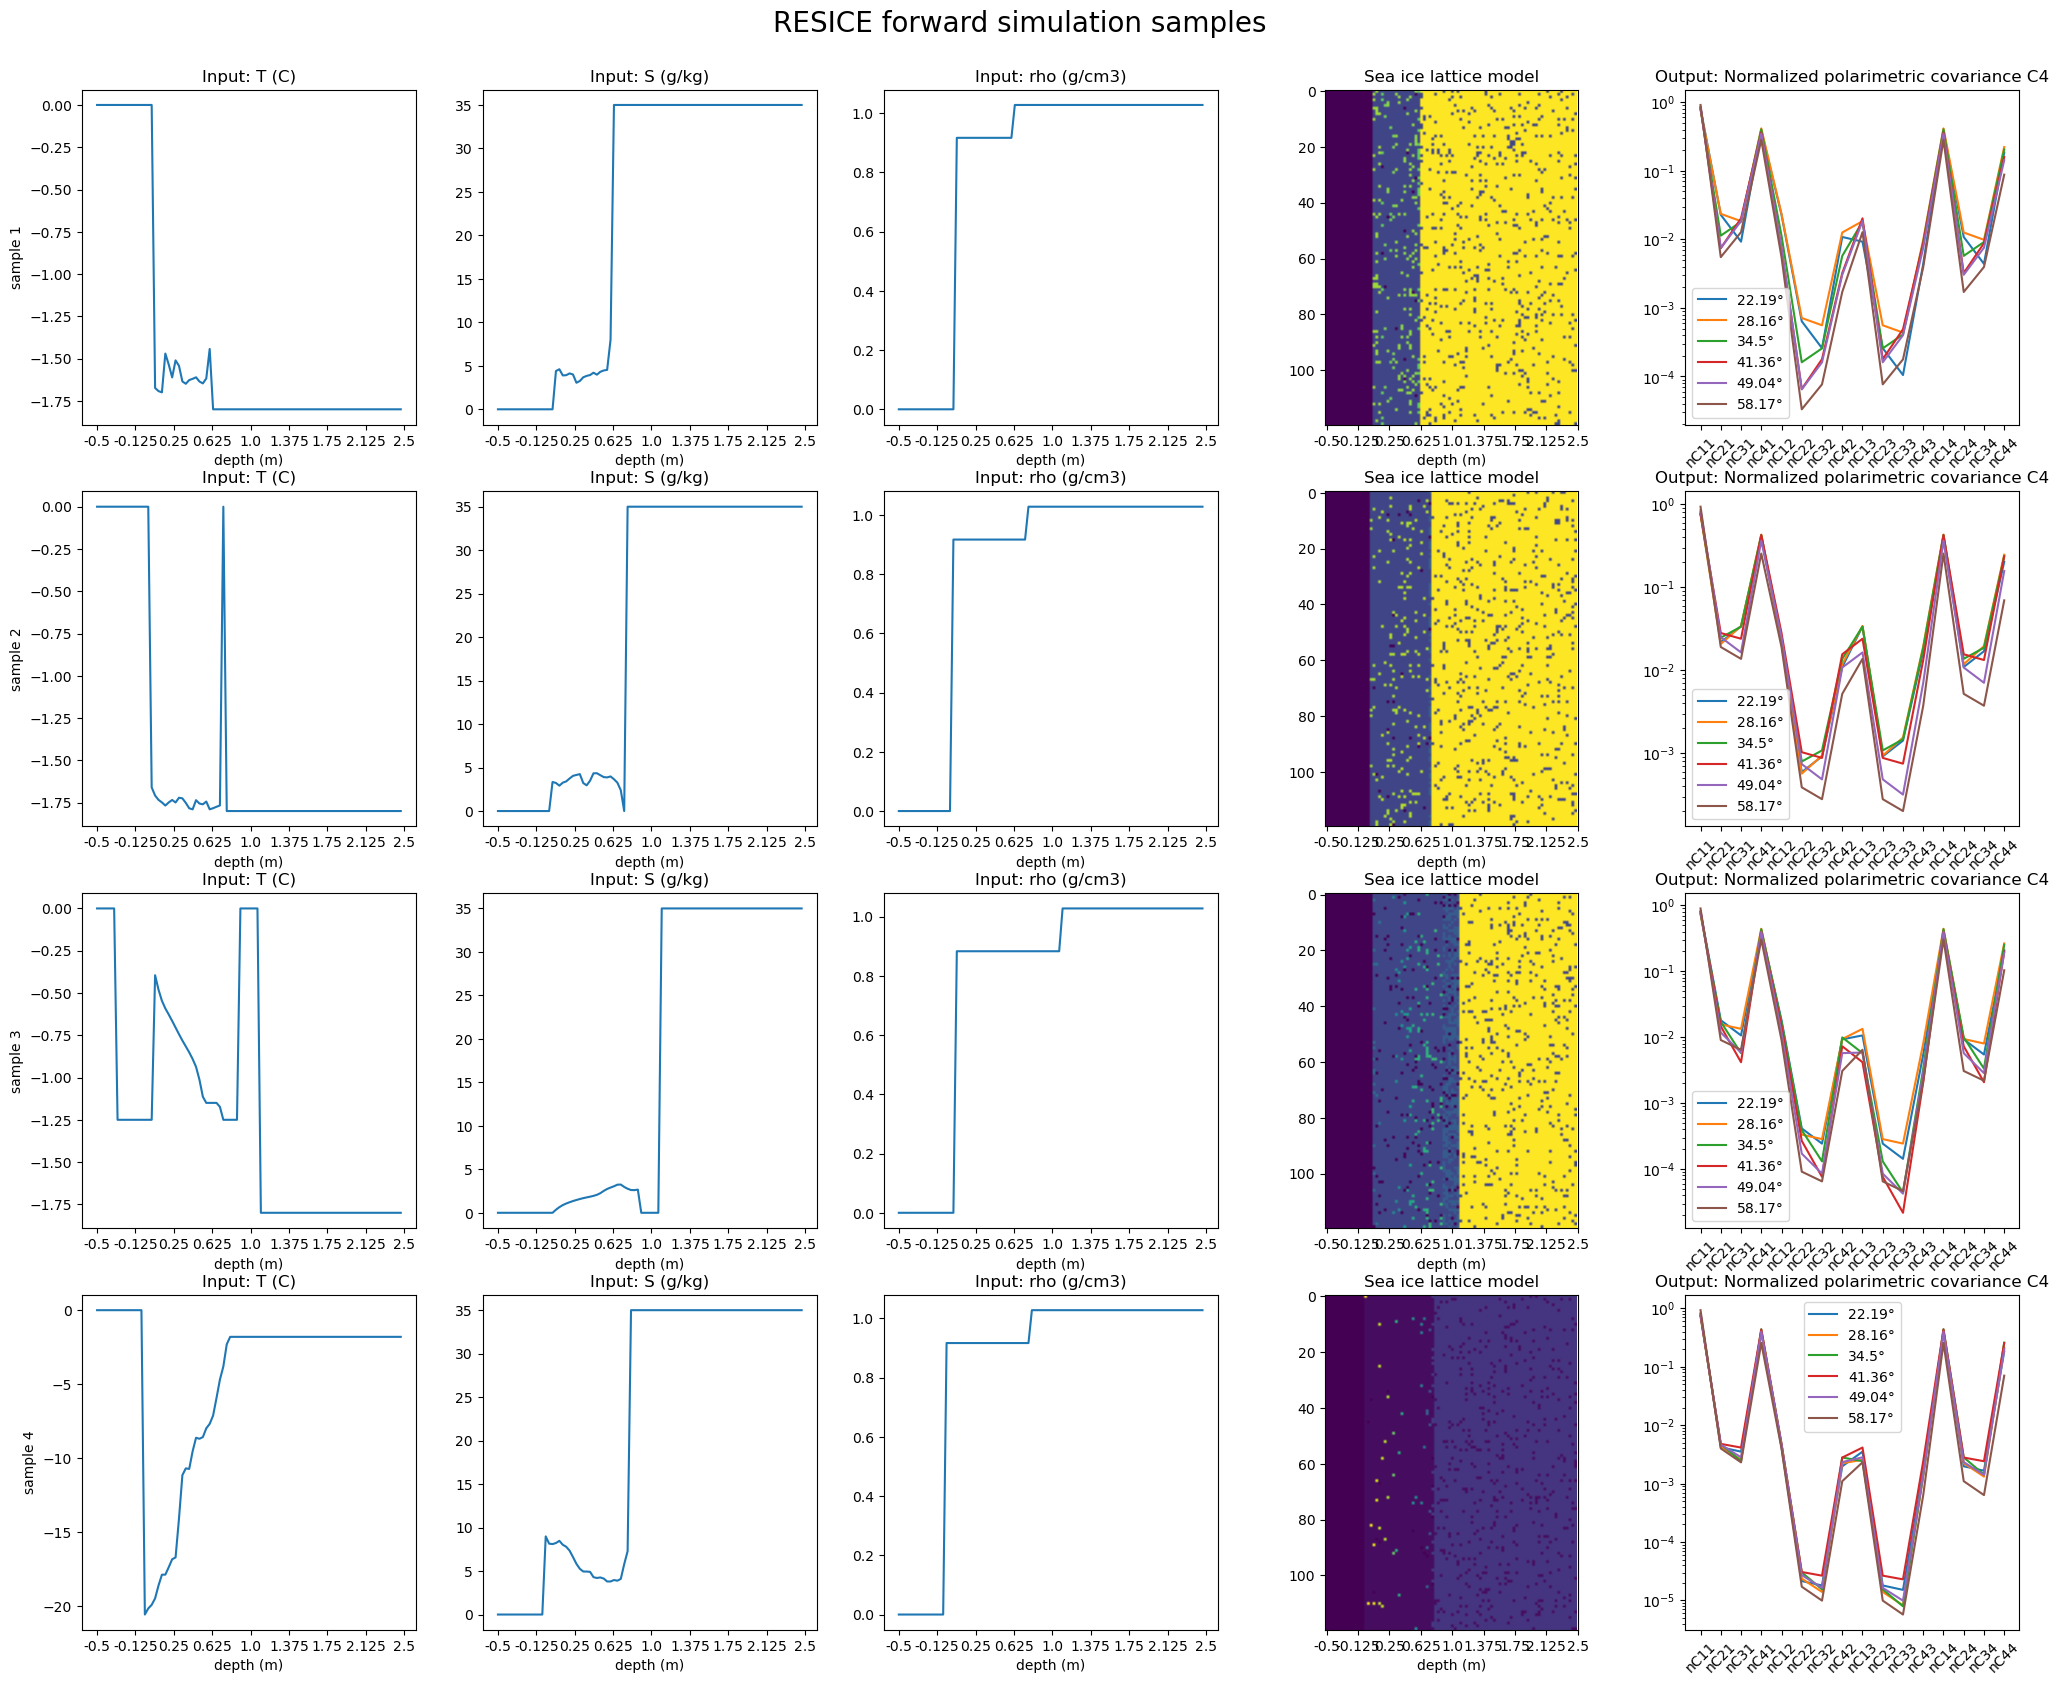

In [136]:
#for sample in feed:
#    
#T,S,rho = feed[8:12,0,:270].view(4,3,90).permute(1,0,2)
#plt.plot(T.cpu()[0])
f_i_t = [10,20,30,40]
plt.figure(figsize=(25,5*len(f_i_t)))
plt.suptitle('RESICE forward simulation samples', y=0.92, fontsize=20)
for i in range(len(f_i_t)):
    spacing = (len(f_i_t)+1) * i
    f_ind = f_i_t[i]
    
    
    S, T, rho = feed[f_ind,0,:270].reshape(3,90)
    xt1, xt2 = np.linspace(0, 90, 9), np.linspace(-0.5, 2.5, 9).round(3).astype(str)
    plt.subplot(len(f_i_t),5,1 + spacing); plt.plot(T.cpu()); plt.title('Input: T (C)'); plt.xticks(xt1, xt2); plt.xlabel('depth (m)'); plt.ylabel(f'sample {i+1}')
    plt.subplot(len(f_i_t),5,2 + spacing); plt.plot(S.cpu()); plt.title('Input: S (g/kg)'); plt.xticks(xt1, xt2); plt.xlabel('depth (m)')
    plt.subplot(len(f_i_t),5,3 + spacing); plt.plot(rho.cpu()); plt.title('Input: rho (g/cm3)'); plt.xticks(xt1, xt2); plt.xlabel('depth (m)')
    
    imm = icesim.gen_lattice(T[None,:], S[None,:], rho[None,:], (1,120))[0,0,1,1:-1,1:-1].cpu()
    imm[imm < 0] = -10
    plt.subplot(len(f_i_t),5,4 + spacing); plt.imshow(imm); plt.title('Sea ice lattice model'); plt.xticks(xt1, xt2); plt.xlabel('depth (m)')
    
    k4 = (feed[f_ind,0,270:270+96] + feed[f_ind,0,270+96:]*1j).reshape(6,-1).cpu()
    plt.subplot(len(f_i_t),5,5 + spacing); plt.plot(k4.abs().T); plt.legend([f'{el}°' for el in floqs]); plt.yscale('log'); plt.title('Output: Normalized polarimetric covariance C4')
    plt.xticks(np.arange(16), np.array([[f'nC{i}{j}' for i in range(1,5)] for j in range(1,5)]).flatten(), rotation=45)
plt.show()


In [118]:
spacing

12